In [1]:
import tqdm
import math
import torch
import numpy as np
from torch import nn
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import seaborn as sns

In [2]:
x0_npy = np.load("../data/trajectories_npy/test01/G1_to_S/x0.npy")
x1_npy = np.load("../data/trajectories_npy/test01/G1_to_S/x1.npy")

In [3]:
class Block(nn.Module):
    def __init__(self, channels=512):
        super().__init__()
        self.ff = nn.Linear(channels, channels)
        self.act = nn.ReLU()

    def forward(self, x):
        return self.act(self.ff(x))

class MLP(nn.Module):
    def __init__(self, channels_data=2, layers=5, channels=512, channels_t=512):
        super().__init__()
        self.channels_t = channels_t
        self.in_projection = nn.Linear(channels_data, channels)
        self.t_projection = nn.Linear(channels_t, channels)
        self.blocks = nn.Sequential(*[
            Block(channels) for _ in range(layers)
        ])
        self.out_projection = nn.Linear(channels, channels_data)

    def gen_t_embedding(self, t, max_positions=10000):
        t = t * max_positions
        half_dim = self.channels_t // 2
        emb = math.log(max_positions) / (half_dim - 1)
        emb = torch.arange(half_dim, device=t.device).float().mul(-emb).exp()
        emb = t[:, None] * emb[None, :]
        emb = torch.cat([emb.sin(), emb.cos()], dim=1)
        if self.channels_t % 2 == 1:  # zero pad
            emb = nn.functional.pad(emb, (0, 1), mode='constant')
        return emb

    def forward(self, x, t):
        x = self.in_projection(x)
        t = self.gen_t_embedding(t)
        t = self.t_projection(t)
        x = x + t
        x = self.blocks(x)
        x = self.out_projection(x)
        return x

# Train or load model

## Train model

In [102]:
model = MLP(layers=5, channels_data=7974, channels=512)
optim = torch.optim.AdamW(model.parameters(), lr=1e-4)

In [103]:
data_x0 = torch.Tensor(x0_npy)
data_x1 = torch.Tensor(x1_npy)

training_steps = 500
batch_size = 64
pbar = tqdm.tqdm(range(training_steps))
losses = []
for i in pbar:
    ids = torch.randint(data_x0.size(0), (batch_size,))
    x0 = data_x0[ids]
    x1 = data_x1[ids]
    target = x1 - x0
    t = torch.rand(x1.size(0))
    xt = (1 - t[:, None]) * x0 + t[:, None] * x1
    pred = model(xt, t)  # also add t here
    loss = ((target - pred)**2).mean()
    loss.backward()
    optim.step()
    optim.zero_grad()
    pbar.set_postfix(loss=loss.item())
    losses.append(loss.item())
    

100%|██████████| 500/500 [00:40<00:00, 12.48it/s, loss=0.0136]


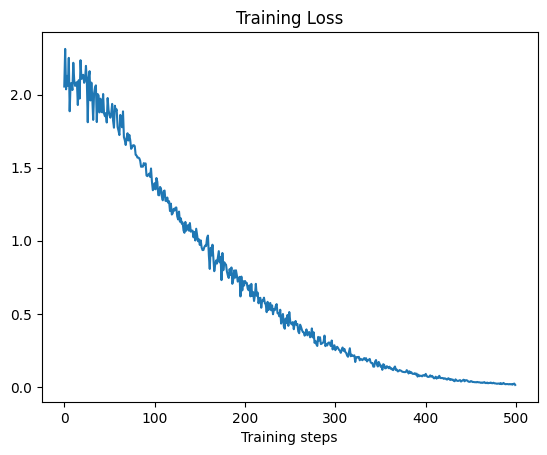

In [104]:
plt.plot(losses)
plt.title("Training Loss")
plt.xlabel("Training steps")
plt.show()

In [96]:
# Save trained model:
torch.save(model.state_dict(), "../models/model_test01.pt")

## Load preexisting model

In [4]:
# Load preptrained model:
model = MLP(layers=5, channels_data=7974, channels=512)
optim = torch.optim.AdamW(model.parameters(), lr=1e-4)
ckpt = torch.load("../models/model_test01.pt")
model.load_state_dict(ckpt)

<All keys matched successfully>

# Iterate trajectory through the vector field

In [5]:
def iterate_trajectory(model, x0, time_steps=100, lr=0.1):
    time_steps = np.linspace(0, 1, time_steps)
    x_curr = x0.copy()
    structures = []
    for i, t in enumerate(time_steps):
        v = model(torch.Tensor(x_curr), torch.Tensor([t])).detach().numpy()
        x_curr = x_curr + v*lr
        if i%10==0:
            structures.append(x_curr)
    return structures

In [38]:
x0_vec = x0_npy[2,:]
x0_3d =  x0_vec.reshape((int(len(x0_vec)/3), 3))
structures = iterate_trajectory(model, x0_vec, time_steps=400, lr=0.01)

In [13]:
import sys
from pathlib import Path

project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))
from src.md.visualization_utils import *

In [39]:
axis_ranges = [x0_3d[:,0].min(), x0_3d[:,0].max(),
               x0_3d[:,1].min(), x0_3d[:,1].max(),
               x0_3d[:,2].min(), x0_3d[:,2].max()]

In [40]:
figs = [visualize_whole_genome(
            points.reshape((int(points.shape[1]/3), 3)), 
            diploid=True, resolution=2_000_000, p=0, title=f"Frame {i}", 
            fig_show=False, axis_range=axis_ranges) \
        for i, points in enumerate(structures)]

In [41]:
create_gif(figs, "./animation.gif", duration=300)

100%|███████████████████████████████████████████| 40/40 [00:57<00:00,  1.45s/it]


# Analyse velocity field

In [179]:
row_id = np.random.randint(x0_npy.shape[0])
coord_id = np.random.randint(x0_npy.shape[1])
x_radius = 10

n = 30
x = np.linspace(x0_npy[row_id, coord_id]-x_radius, x0_npy[row_id, coord_id]+x_radius, n)
t = np.linspace(0, 1, n)
v_field = np.zeros((n, n))

x0_row = x0_npy[row_id,:].copy()
for i in range(n):
    for j in range(n):
        v = model(torch.Tensor(x0_row + x[i]), torch.Tensor([t[j]])).detach().numpy()[0, coord_id]
        v_field[i, j] = v


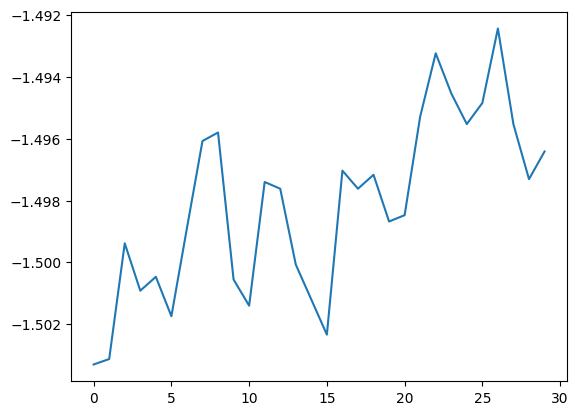

In [178]:
plt.plot(v_field[15,:])

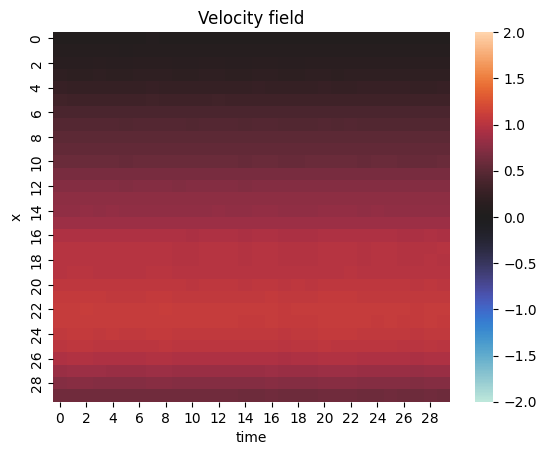

In [180]:
sns.heatmap(v_field, vmin=-2, vmax=2, cmap="icefire")
plt.title("Velocity field")
plt.xlabel("time")
plt.ylabel("x")
plt.show()

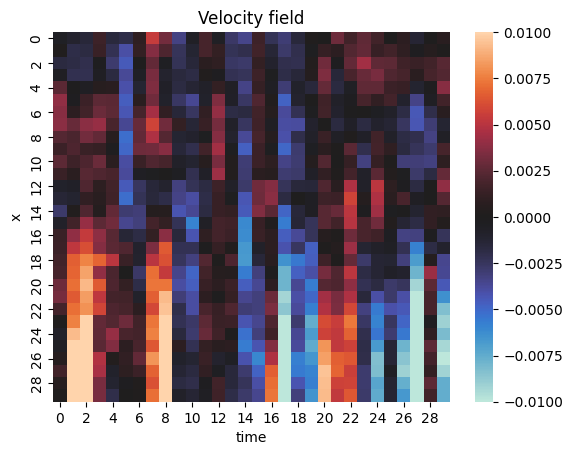

In [184]:
sns.heatmap(v_field -v_field.mean(axis=1, keepdims=True), vmin=-0.01, vmax=0.01, cmap="icefire")
plt.title("Velocity field")
plt.xlabel("time")
plt.ylabel("x")
plt.show()